### K-Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) is a **supervised, instance-based learning algorithm** used for classification and regression. It does not learn a traditional equation during training. Instead, it stores the training examples and predicts a new sample by finding the `k` closest training samples.

For classification, KNN assigns the class that receives the majority vote among the nearest neighbors. For regression, it commonly predicts the average target value of those neighbors.

The result depends on the choice of `k`, the distance metric, and feature scales. Since KNN relies on distances, feature scaling is usually important.

#### Euclidean Distance

For two observations with $n$ features, Euclidean distance is:

$$
d(\mathbf{x},\mathbf{y}) =
\sqrt{\sum_{i=1}^{n}(x_i-y_i)^2}
$$

KNN uses this distance to identify which training observations are closest to a new observation.

#### Advantages and Disadvantages of KNN

**Advantages**
- Simple and intuitive to understand.
- No explicit model-training phase is required; it stores the training data.
- Can model non-linear decision boundaries.
- Supports classification and regression.

**Disadvantages**
- Prediction can be slow on large datasets because distances to training observations must be calculated.
- Requires feature scaling when features have different ranges.
- Sensitive to the choice of `k`, distance metric, and irrelevant features.
- Can perform poorly with many features because distances become less informative in high-dimensional spaces.
- Requires storing the training dataset in memory.

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_csv('Datasets/cancer.csv')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
df.drop(columns=['id','Unnamed: 32'],inplace=True)
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:,1:], df.iloc[:,0],test_size=0.2, random_state=2)

In [5]:
X_train.shape

(455, 30)

#### Feature Scaling

KNN calculates distances between observations. If one feature has much larger numerical values than another, it can dominate the distance calculation.

`StandardScaler` transforms each feature using the training-set mean and standard deviation. The scaler is fitted only on `X_train`, then the same transformation is applied to `X_test`. This avoids using test-set information during preprocessing.

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [7]:
X_train

array([[-0.01330339,  1.7757658 , -0.01491962, ..., -0.13236958,
        -1.08014517, -0.03527943],
       [-0.8448276 , -0.6284278 , -0.87702746, ..., -1.11552632,
        -0.85773964, -0.72098905],
       [ 1.44755936,  0.71180168,  1.47428816, ...,  0.87583964,
         0.4967602 ,  0.46321706],
       ...,
       [-0.46608541, -1.49375484, -0.53234924, ..., -1.32388956,
        -1.02997851, -0.75145272],
       [-0.50025764, -1.62161319, -0.527814  , ..., -0.0987626 ,
         0.35796577, -0.43906159],
       [ 0.96060511,  1.21181916,  1.00427242, ...,  0.8956983 ,
        -1.23064515,  0.50697397]])

#### Train a KNN Classifier

`KNeighborsClassifier(n_neighbors=3)` uses the three nearest training observations to classify each new sample.

**How prediction works:**
1. Calculate the distance from the new observation to every training observation.
2. Select the `k` observations with the smallest distances.
3. Count the class labels among those neighbors.
4. Predict the majority class.

The default distance for this Scikit-learn classifier is Minkowski distance with `p=2`, which is Euclidean distance.

In [8]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)

In [9]:
knn.fit(X_train,y_train)

KNeighborsClassifier(n_neighbors=3)

In [10]:
from sklearn.metrics import accuracy_score

y_pred = knn.predict(X_test)

accuracy_score(y_test, y_pred)

0.9912280701754386

#### How to Select the Value of K?

A small `k` can make the model sensitive to noise and individual observations. A large `k` creates smoother decision boundaries but may overlook local patterns.

The notebook compares accuracy for `k` values from 1 to 15 and plots the results.

**Evaluation note:** The current code uses the test set to compare many `k` values. This makes the test set part of model selection and can lead to an optimistic final score. A better approach is to choose `k` using cross-validation on the training set, then evaluate the selected model once on the test set.

In [11]:
scores = []

for i in range(1,16):
    
    knn = KNeighborsClassifier(n_neighbors=i)
    
    knn.fit(X_train,y_train)
    
    y_pred = knn.predict(X_test)

    scores.append(accuracy_score(y_test, y_pred))

Text(0, 0.5, 'Accuaracy Score')

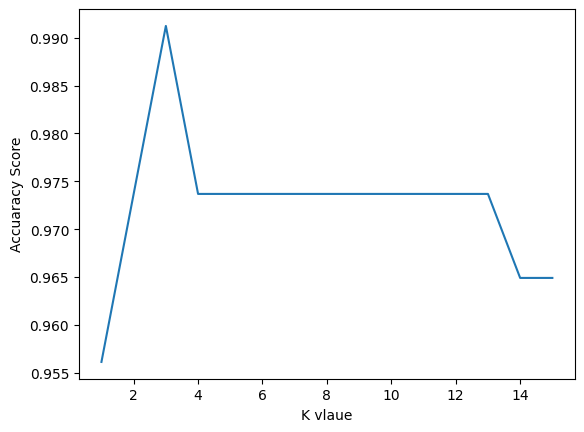

In [12]:
plt.plot(range(1,16),scores)
plt.xlabel("K vlaue")
plt.ylabel("Accuaracy Score")

In [13]:
y_train

560    B
428    B
198    M
203    M
41     M
      ..
299    B
534    B
493    B
527    B
168    M
Name: diagnosis, Length: 455, dtype: object

#### Implement KNN from Scratch

The custom `KNN` class demonstrates the core algorithm without using Scikit-learn's classifier.

- `fit()` stores the training features and labels.
- `calculate_distance()` calculates Euclidean distance using NumPy's `linalg.norm`.
- `predict()` finds the nearest training observations for each test sample.
- `majority_count()` uses `Counter` to select the most common label.

This implementation makes the algorithm easier to understand. It uses a straightforward loop-based approach, which is useful for learning but is not as optimized as Scikit-learn for large datasets.

In [14]:
from collections import Counter
import numpy as np

class KNN:

    def __init__(self, k=5):
        self.n_neighbors = k
        self.X_train = None
        self.y_train = None

    def fit(self, X_train, y_train):

        # Convert training data into NumPy arrays
        self.X_train = np.asarray(X_train)
        self.y_train = np.asarray(y_train)

    def predict(self, X_test):
        y_pred = []
        for i in X_test:

            # Calculate distance with each training point
            distances = []
            for j in self.X_train:
                distances.append(self.calculate_distance(i, j))

            # Find nearest neighbors
            n_neighbors = sorted(
                enumerate(distances),
                key=lambda x: x[1]
            )[:self.n_neighbors]

            # Majority voting
            label = self.majority_count(n_neighbors)
            y_pred.append(label)

        return np.array(y_pred)

    def calculate_distance(self, point_A, point_B):
        return np.linalg.norm(point_A - point_B)

    def majority_count(self, neighbors):
        votes = []
        for i in neighbors:
            votes.append(self.y_train[i[0]])
        votes = Counter(votes)
        return votes.most_common(1)[0][0]


In [15]:
apnaknn = KNN(k=3)

In [16]:
apnaknn.fit(X_train,y_train)

In [17]:
y_pred1 = apnaknn.predict(X_test)
accuracy_score(y_test, y_pred1)

0.9912280701754386

#### Visualize the KNN Decision Surface

This section uses two features from the Iris dataset and plots the regions where the trained KNN classifier predicts each class.

A decision surface shows how the model divides the feature space into predicted classes. The boundary changes when `k` changes: smaller values often create more irregular boundaries, while larger values tend to create smoother regions.

Training Accuracy: 0.9666666666666667
Testing Accuracy: 0.9


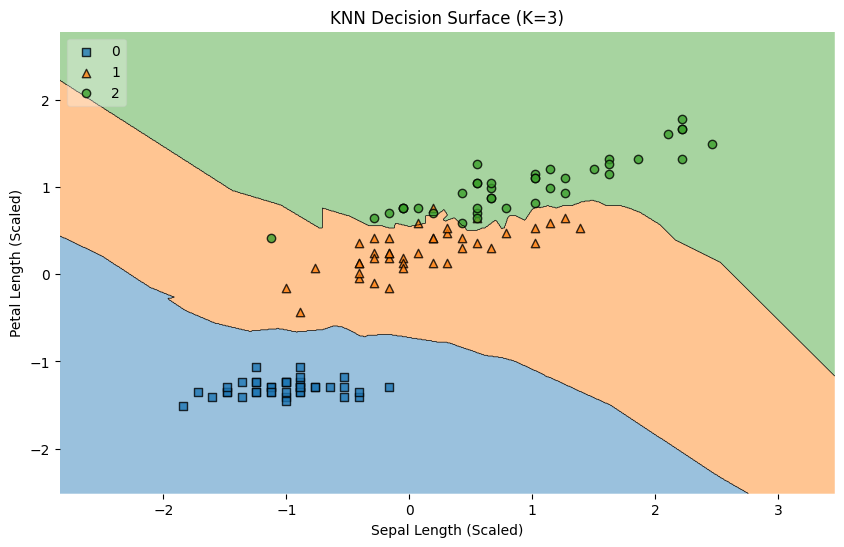

In [18]:
from sklearn.datasets import load_iris
from mlxtend.plotting import plot_decision_regions

iris = load_iris()

X = iris.data[:, [0, 2]]
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# Feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

print("Training Accuracy:", knn.score(X_train, y_train))
print("Testing Accuracy:", knn.score(X_test, y_test))


# Plot decision surface
plt.figure(figsize=(10, 6))

plot_decision_regions(
    X=X_train,
    y=y_train,
    clf=knn,
    legend=2
)

plt.xlabel("Sepal Length (Scaled)")
plt.ylabel("Petal Length (Scaled)")
plt.title("KNN Decision Surface (K=3)")

plt.show()

#### Interactive Decision Boundary

The final section creates an interactive plot using `ipywidgets`. A slider changes the number of neighbors, and the decision boundary is redrawn for the selected `k`.

The visualization uses two standardized features from Scikit-learn's breast cancer dataset. It helps demonstrate how changing `k` affects the shape of the classification regions.

In [19]:
from ipywidgets import interact, fixed
import ipywidgets as widgets

from sklearn import datasets, neighbors
from sklearn.preprocessing import StandardScaler
from matplotlib.colors import ListedColormap

from IPython.display import display, clear_output

def load_data():
    cancer = datasets.load_breast_cancer()
    return cancer

def plot_decision_boundaries(n_neighbors, data, labels):

    h = 0.02

    cmap_light = ListedColormap(['orange', 'blue'])
    cmap_bold = ListedColormap(['darkorange', 'darkblue'])

    # Create KNN classifier
    clf = neighbors.KNeighborsClassifier(n_neighbors=n_neighbors)

    # Train model
    clf.fit(data, labels)

    # Define plot boundaries
    x_min, x_max = data[:, 0].min() - 1, data[:, 0].max() + 1
    y_min, y_max = data[:, 1].min() - 1, data[:, 1].max() + 1

    # Create meshgrid
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, h),
        np.arange(y_min, y_max, h)
    )

    # Predict meshgrid points
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plot decision surface
    plt.figure(figsize=(8, 6))

    plt.pcolormesh(
        xx, yy, Z,
        cmap=cmap_light,
        shading='auto'
    )

    # Plot actual data points
    plt.scatter(
        data[:, 0],
        data[:, 1],
        c=labels,
        cmap=cmap_bold,
        edgecolor='k',
        s=20
    )

    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())

    plt.xlabel("Mean Radius (Scaled)")
    plt.ylabel("Mean Texture (Scaled)")

    plt.title(f'2-Class Classification (K = {n_neighbors})')

    plt.show()


cancer = load_data()

# Select first two features and standardize
X = StandardScaler().fit_transform(cancer.data[:, :2])

y = cancer.target


# Create interactive slider
slider = widgets.IntSlider(
    value=10,
    min=1,
    max=20,
    step=1,
    description='K Neighbors:',
    continuous_update=False
)


# Connect slider with plotting function
output = widgets.interactive_output(
    plot_decision_boundaries,
    {
        'n_neighbors': slider,
        'data': widgets.fixed(X),
        'labels': widgets.fixed(y)
    }
)


# Display slider and plot
display(slider, output)


IntSlider(value=10, continuous_update=False, description='K Neighbors:', max=20, min=1)

Output()

#### Key Takeaways

- KNN predicts using the labels or values of the nearest training observations.
- `k` controls how many neighbors contribute to a prediction.
- Feature scaling is important because KNN is distance-based.
- Choose `k` using cross-validation on training data, not by repeatedly checking test-set accuracy.
- Use a separate test set for the final evaluation.